# HyFleet: hydrogen readiness analytics for a UK SME haulier

**Question.** Which trucks in a 60-vehicle diesel fleet should switch to hydrogen first, and what would hydrogen have to cost for the switch to pay?

**Data.** One year of simulated duty data (about 16,000 vehicle-days) for a fictional haulier with depots in Bradford, Wakefield and Hull. The simulation is calibrated to DfT road freight statistics (about 7.9 mpg for artics, 9.1 mpg for rigids) and to UK Government weekly pump prices (about 141p to 200p per litre in the year to November 2026). Data-quality problems are injected on purpose.

**Contents.**

1. Setup and data generation
2. Data profiling
3. Cleaning pipeline
4. SQL analysis (SQLite)
5. Vehicle and fleet KPIs
6. Exploratory charts
7. Decision model: break-even, sensitivity grid, Monte Carlo, readiness ranking
8. Findings and limitations

## 1. Setup and data generation

In [1]:
import sqlite3
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

# Work out the project root whether you run from /notebooks or the root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN, FIG = ROOT / "data" / "raw", ROOT / "data" / "clean", ROOT / "figures"
for folder in (RAW, CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)

# Display and chart settings
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Project constants (all in one place, so they are easy to change)
H2_RANGE_KM = 400      # assumed usable range of a hydrogen HGV on one fill
CO2E_PER_L = 2.55      # kg CO2e per litre of diesel (DESNZ, average biofuel blend)
VAT = 1.20             # hauliers reclaim VAT, so we cost diesel ex VAT

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


In [2]:
result = subprocess.run([sys.executable, str(ROOT / "src" / "generate_data.py")],
                        capture_output=True, text=True, check=True)
print(result.stdout)

depots: 3, vehicles: 60, price weeks: 52, duty rows: 16,124



## 2. Data profiling

Inspect before changing anything. The checks below surface seven issues: inconsistent depot names, duplicate uploads, two date formats, mixed distance units, impossible distances, fuel readings keyed ten times too high, and missing fuel and payload values.

In [3]:
depots = pd.read_csv(RAW / "depots.csv")
vehicles = pd.read_csv(RAW / "vehicles.csv")
prices = pd.read_csv(RAW / "diesel_prices.csv", parse_dates=["week_start"])
duties_raw = pd.read_csv(RAW / "duties.csv")

for name, frame in {"depots": depots, "vehicles": vehicles,
                    "prices": prices, "duties": duties_raw}.items():
    print(f"{name:<9} {frame.shape[0]:>6,} rows x {frame.shape[1]} columns")

depots         3 rows x 4 columns
vehicles      60 rows x 8 columns
prices        52 rows x 2 columns
duties    16,124 rows x 11 columns


In [4]:
duties_raw.head()

,duty_id,vehicle_id,duty_date,distance,payload_t,empty_km_share,fuel_litres,duty_hours,returned_to_base,telematics_source,distance_unit
0,T000001,V001,2025-11-24,109.40,6.82,0.26,36.50,3.59,True,A,km
1,T000002,V004,2025-11-24,109.40,7.28,0.28,32.90,2.75,True,A,km
2,T000003,V005,2025-11-24,284.00,12.50,0.15,950.00,5.78,True,A,km
3,T000004,V006,2025-11-24,138.20,8.08,0.23,44.60,4.03,True,A,km
4,T000005,V007,24/11/2025,71.10,6.15,0.37,36.50,3.77,True,B,mi


In [5]:
duties_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
distance,"16,124.00",258.74,132.27,-699.60,155.60,228.30,342.70,719.00
payload_t,"15,794.00",12.01,5.71,0.45,7.14,11.37,16.29,26.00
empty_km_share,"16,124.00",0.30,0.10,0.00,0.23,0.30,0.37,0.71
fuel_litres,"15,640.00",97.73,75.66,16.80,54.10,81.45,130.50,"2,434.00"
duty_hours,"16,124.00",6.23,2.24,2.18,4.50,5.70,7.68,15.00


In [6]:
print("Missing values per column:")
print(duties_raw.isna().sum()[lambda s: s > 0])

print("\nExact duplicate rows:", duties_raw.duplicated().sum())
print("Distances <= 0:      ", (duties_raw["distance"] <= 0).sum())

print("\nUnits by telematics source:")
print(duties_raw[["telematics_source", "distance_unit"]].value_counts())

Missing values per column:
payload_t      330
fuel_litres    484
dtype: int64

Exact duplicate rows: 191
Distances <= 0:       35

Units by telematics source:
telematics_source  distance_unit
A                  km               13671
B                  mi                2453
Name: count, dtype: int64


In [7]:
print("Date formats (a random sample):")
print(duties_raw.groupby("telematics_source")["duty_date"].first())

print("\nHow depot names were typed:")
print(vehicles["home_depot"].value_counts())

Date formats (a random sample):
telematics_source
A    2025-11-24
B    24/11/2025
Name: duty_date, dtype: str

How depot names were typed:
home_depot
Wakefield           14
 Bradford Depot      8
wakefield            8
Bradford             7
 Wakefield Depot     5
 Hull Depot          4
BRADFORD             4
Hull                 4
bradford             2
HULL                 2
WAKEFIELD            2
Name: count, dtype: int64


## 3. Cleaning pipeline

Each step is logged with the number of rows it touched and guarded with an `assert`. Fuel outliers are found with a 3 × IQR rule on litres per 100 km. Missing values are filled from each vehicle's own median, and flagged.

In [8]:
log = []
def log_step(step, rows):
    log.append({"step": step, "rows_affected": int(rows)})

duties = duties_raw.copy()

**Depot names:** standardise free text, then map to IDs.

In [9]:
clean_name = (vehicles["home_depot"]
              .str.strip()
              .str.lower()
              .str.replace(" depot", "", regex=False)
              .str.title())
print(clean_name.value_counts())

name_to_id = dict(zip(depots["depot_name"], depots["depot_id"]))
vehicles["depot_id"] = clean_name.map(name_to_id)

assert vehicles["depot_id"].notna().all(), "Some depot names did not match"
log_step("Standardised depot names", (vehicles["home_depot"] != clean_name).sum())
vehicles = vehicles.drop(columns="home_depot")

home_depot
Wakefield    29
Bradford     21
Hull         10
Name: count, dtype: int64


**Duplicates.**

In [10]:
n_dupes = duties.duplicated().sum()
duties = duties.drop_duplicates().reset_index(drop=True)
assert duties["duty_id"].is_unique
log_step("Dropped duplicate uploads", n_dupes)
print(f"Removed {n_dupes} duplicates. Rows now: {len(duties):,}")

Removed 191 duplicates. Rows now: 15,933


**Dates:** parse each provider's format explicitly rather than letting pandas guess.

In [11]:
iso = pd.to_datetime(duties["duty_date"], format="%Y-%m-%d", errors="coerce")
uk = pd.to_datetime(duties["duty_date"], format="%d/%m/%Y", errors="coerce")
duties["duty_date"] = iso.fillna(uk)

assert duties["duty_date"].notna().all()
log_step("Parsed UK-format dates", uk.notna().sum())
print("Date range:", duties["duty_date"].min().date(), "to", duties["duty_date"].max().date())
print("Type now:", duties["duty_date"].dtype)

Date range: 2025-11-24 to 2026-11-21
Type now: datetime64[us]


**Units:** provider B reports miles.

In [12]:
in_miles = duties["distance_unit"].eq("mi")
duties["distance_km"] = np.where(in_miles, duties["distance"] * 1.609344,
                                 duties["distance"]).round(1)
duties = duties.drop(columns=["distance", "distance_unit"])
log_step("Converted miles to km", in_miles.sum())

# Check: the two providers should now look alike
duties.groupby("telematics_source")["distance_km"].median()

telematics_source
A   241.90
B   227.90
Name: distance_km, dtype: float64

**Impossible distances.**

In [13]:
bad_distance = duties["distance_km"] <= 0
duties = duties.loc[~bad_distance].copy()
log_step("Removed zero or negative distances", bad_distance.sum())

**Fuel outliers** (3 × IQR on l/100km), blanked rather than dropped so the distance is kept.

In [14]:
duties["l_per_100km"] = duties["fuel_litres"] / duties["distance_km"] * 100

q1, q3 = duties["l_per_100km"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 3 * iqr, q3 + 3 * iqr
print(f"Normal range: {low:.1f} to {high:.1f} l/100km")

outlier = duties["l_per_100km"].notna() & ~duties["l_per_100km"].between(low, high)
duties.loc[outlier, ["duty_id", "vehicle_id", "distance_km", "fuel_litres", "l_per_100km"]].head()

Normal range: 15.9 to 51.5 l/100km


,duty_id,vehicle_id,distance_km,fuel_litres,l_per_100km
2,T000003,V005,284.00,950.00,334.51
19,T000020,V022,252.90,821.00,324.63
466,T000467,V004,113.20,367.00,324.20
1064,T001065,V056,123.60,403.00,326.05
1137,T001138,V021,211.60,671.00,317.11


In [15]:
duties.loc[outlier, "fuel_litres"] = np.nan
log_step("Blanked fuel decimal slips", outlier.sum())

**Imputation** from each vehicle's median rate, with flag columns.

In [16]:
duties["fuel_imputed"] = duties["fuel_litres"].isna()
veh_rate = (duties["fuel_litres"] / duties["distance_km"] * 100).groupby(duties["vehicle_id"]).transform("median")
duties["fuel_litres"] = duties["fuel_litres"].fillna(duties["distance_km"] * veh_rate / 100).round(1)
duties["l_per_100km"] = duties["fuel_litres"] / duties["distance_km"] * 100
log_step("Imputed missing fuel", duties["fuel_imputed"].sum())

duties["payload_imputed"] = duties["payload_t"].isna()
veh_payload = duties.groupby("vehicle_id")["payload_t"].transform("median")
duties["payload_t"] = duties["payload_t"].fillna(veh_payload)
log_step("Imputed missing payload", duties["payload_imputed"].sum())

**Final checks and save.**

In [17]:
assert duties[["duty_date", "distance_km", "fuel_litres", "payload_t"]].notna().all().all()
assert (duties["distance_km"] > 0).all()
assert duties["l_per_100km"].between(15, 60).all()
assert duties["vehicle_id"].isin(vehicles["vehicle_id"]).all()

duties.to_csv(CLEAN / "duties.csv", index=False)
vehicles.to_csv(CLEAN / "vehicles.csv", index=False)
depots.to_csv(CLEAN / "depots.csv", index=False)
prices.to_csv(CLEAN / "diesel_prices.csv", index=False)

cleaning_log = pd.DataFrame(log)
cleaning_log.to_csv(CLEAN / "cleaning_log.csv", index=False)
print(f"Clean duties: {len(duties):,} rows (raw: {len(duties_raw):,})")
cleaning_log

Clean duties: 15,898 rows (raw: 16,124)


,step,rows_affected
0,Standardised depot names,35
1,Dropped duplicate uploads,191
2,Parsed UK-format dates,2419
3,Converted miles to km,2419
4,Removed zero or negative distances,35
5,Blanked fuel decimal slips,45
6,Imputed missing fuel,519
7,Imputed missing payload,322


## 4. SQL analysis (SQLite)

The clean tables are loaded into SQLite. Queries cover filtering, aggregation, joins, CASE banding, CTEs, window functions and date logic. Every query is also in `sql/queries.sql`.

In [18]:
con = sqlite3.connect(ROOT / "data" / "fleet.db")

(duties.assign(duty_date=duties["duty_date"].dt.strftime("%Y-%m-%d"))
       .to_sql("duties", con, if_exists="replace", index=False))
vehicles.to_sql("vehicles", con, if_exists="replace", index=False)
depots.to_sql("depots", con, if_exists="replace", index=False)
(prices.assign(week_start=prices["week_start"].dt.strftime("%Y-%m-%d"))
       .to_sql("diesel_prices", con, if_exists="replace", index=False))

def sql(query: str) -> pd.DataFrame:
    """Run a SQL query against fleet.db and return a DataFrame."""
    return pd.read_sql_query(query, con)

sql("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,duties
1,vehicles
2,depots
3,diesel_prices


In [19]:
sql("""
SELECT duty_id, vehicle_id, duty_date, distance_km, fuel_litres
FROM duties
WHERE distance_km > 600
ORDER BY distance_km DESC
LIMIT 5;
""")

,duty_id,vehicle_id,duty_date,distance_km,fuel_litres
0,T012874,V060,2026-09-12,719.10,278.80
1,T013651,V027,2026-10-01,719.00,284.60
2,T012040,V047,2026-08-25,718.40,240.50
3,T000087,V038,2025-11-25,716.00,257.40
4,T007216,V015,2026-05-07,715.50,248.50


In [20]:
sql("""
SELECT vehicle_id,
       COUNT(*)                   AS duties,
       ROUND(SUM(distance_km))    AS annual_km,
       ROUND(AVG(distance_km), 1) AS avg_daily_km
FROM duties
GROUP BY vehicle_id
HAVING SUM(distance_km) > 100000
ORDER BY annual_km DESC;
""")

,vehicle_id,duties,annual_km,avg_daily_km
0,V050,274,"117,126.00",427.50
1,V057,269,"116,696.00",433.80
2,V051,264,"116,076.00",439.70
3,V060,271,"115,497.00",426.20
4,V047,270,"114,427.00",423.80
5,V048,269,"114,386.00",425.20
6,V033,264,"114,386.00",433.30
7,V038,265,"113,879.00",429.70
8,V015,267,"113,404.00",424.70
9,V059,266,"113,355.00",426.10


In [21]:
sql("""
SELECT dp.depot_name,
       v.vehicle_type,
       COUNT(DISTINCT v.vehicle_id)                         AS vehicles,
       ROUND(SUM(d.distance_km))                            AS total_km,
       ROUND(100.0 * SUM(d.fuel_litres) / SUM(d.distance_km), 1) AS l_per_100km
FROM duties d
JOIN vehicles v  ON d.vehicle_id = v.vehicle_id
JOIN depots   dp ON v.depot_id   = dp.depot_id
GROUP BY dp.depot_name, v.vehicle_type
ORDER BY dp.depot_name, v.vehicle_type;
""")

,depot_name,vehicle_type,vehicles,total_km,l_per_100km
0,Bradford,artic,13,"1,260,143.00",36.60
1,Bradford,rigid,8,"433,504.00",31.50
2,Hull,artic,4,"351,197.00",35.80
3,Hull,rigid,6,"301,742.00",30.40
4,Wakefield,artic,15,"1,399,531.00",35.80
5,Wakefield,rigid,14,"625,632.00",31.20


In [22]:
sql("""
SELECT CASE
         WHEN distance_km <= 200 THEN '1: up to 200 km'
         WHEN distance_km <= 400 THEN '2: 201 to 400 km'
         ELSE '3: over 400 km'
       END AS range_band,
       COUNT(*) AS duties,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM duties), 1) AS pct_of_duties
FROM duties
GROUP BY range_band
ORDER BY range_band;
""")

,range_band,duties,pct_of_duties
0,1: up to 200 km,5687,35.80
1,2: 201 to 400 km,7068,44.50
2,3: over 400 km,3143,19.80


In [23]:
sql("""
WITH vehicle_km AS (
    SELECT v.depot_id, d.vehicle_id, SUM(d.distance_km) AS annual_km
    FROM duties d
    JOIN vehicles v USING (vehicle_id)
    GROUP BY v.depot_id, d.vehicle_id
),
ranked AS (
    SELECT depot_id, vehicle_id, ROUND(annual_km) AS annual_km,
           RANK() OVER (PARTITION BY depot_id ORDER BY annual_km DESC) AS rank_in_depot,
           ROUND(100.0 * annual_km / SUM(annual_km) OVER (PARTITION BY depot_id), 1) AS pct_of_depot_km
    FROM vehicle_km
)
SELECT * FROM ranked
WHERE rank_in_depot <= 3
ORDER BY depot_id, rank_in_depot;
""")

,depot_id,vehicle_id,annual_km,rank_in_depot,pct_of_depot_km
0,D01,V050,"117,126.00",1,6.90
1,D01,V048,"114,386.00",2,6.80
2,D01,V015,"113,404.00",3,6.70
3,D02,V057,"116,696.00",1,5.80
4,D02,V051,"116,076.00",2,5.70
5,D02,V060,"115,497.00",3,5.70
6,D03,V047,"114,427.00",1,17.50
7,D03,V027,"111,548.00",2,17.10
8,D03,V005,"64,149.00",3,9.80


In [24]:
monthly_cost_sql = sql("""
WITH duty_week AS (
    SELECT d.*, date(d.duty_date, '-6 days', 'weekday 1') AS week_start
    FROM duties d
)
SELECT strftime('%Y-%m', dw.duty_date)                        AS month,
       ROUND(SUM(dw.fuel_litres))                             AS litres,
       ROUND(AVG(p.pump_ppl), 1)                              AS avg_pump_ppl,
       ROUND(SUM(dw.fuel_litres * p.pump_ppl / 100 / 1.2))    AS fuel_cost_gbp
FROM duty_week dw
JOIN diesel_prices p ON dw.week_start = p.week_start
GROUP BY month
ORDER BY month;
""")
monthly_cost_sql

,month,litres,avg_pump_ppl,fuel_cost_gbp
0,2025-11,"28,666.00",145.80,"34,839.00"
1,2025-12,"133,614.00",144.00,"160,380.00"
2,2026-01,"135,664.00",140.80,"159,129.00"
3,2026-02,"120,479.00",142.30,"142,890.00"
4,2026-03,"122,772.00",160.10,"163,761.00"
5,2026-04,"128,190.00",187.50,"200,295.00"
6,2026-05,"124,552.00",186.30,"193,333.00"
7,2026-06,"125,751.00",183.40,"192,219.00"
8,2026-07,"128,516.00",182.30,"195,230.00"
9,2026-08,"123,277.00",183.70,"188,755.00"


In [25]:
check = sql("""
SELECT (SELECT COUNT(*) FROM duties) AS duties_total,
       COUNT(*) AS duties_matched_to_a_price
FROM duties d
JOIN diesel_prices p ON date(d.duty_date, '-6 days', 'weekday 1') = p.week_start;
""")
check

,duties_total,duties_matched_to_a_price
0,15898,15898


## 5. Vehicle and fleet KPIs

One analysis table (duties joined to vehicles, depots and weekly prices, with validated many-to-one merges), fleet headline KPIs, one row per vehicle, and a cross-check that SQL and pandas agree.

In [26]:
df = (duties
      .merge(vehicles, on="vehicle_id", how="left", validate="many_to_one")
      .merge(depots, on="depot_id", how="left", validate="many_to_one"))

# Monday at the start of each duty's week, then join the weekly price
df["week_start"] = df["duty_date"] - pd.to_timedelta(df["duty_date"].dt.dayofweek, unit="D")
df = df.merge(prices, on="week_start", how="left", validate="many_to_one")
assert len(df) == len(duties) and df["pump_ppl"].notna().all()

df["diesel_gbp_per_l"] = df["pump_ppl"] / 100 / VAT
df["fuel_cost_gbp"] = df["fuel_litres"] * df["diesel_gbp_per_l"]
df["co2e_kg"] = df["fuel_litres"] * CO2E_PER_L
df["within_h2_range"] = df["distance_km"] <= H2_RANGE_KM
df["month"] = df["duty_date"].dt.to_period("M")

df[["duty_id", "vehicle_id", "depot_name", "duty_date", "distance_km",
    "fuel_litres", "pump_ppl", "fuel_cost_gbp"]].head()

,duty_id,vehicle_id,depot_name,duty_date,distance_km,fuel_litres,pump_ppl,fuel_cost_gbp
0,T000001,V001,Wakefield,2025-11-24,109.40,36.50,145.84,44.36
1,T000002,V004,Wakefield,2025-11-24,109.40,32.90,145.84,39.98
2,T000003,V005,Hull,2025-11-24,284.00,98.50,145.84,119.71
3,T000004,V006,Wakefield,2025-11-24,138.20,44.60,145.84,54.20
4,T000005,V007,Bradford,2025-11-24,114.40,36.50,145.84,44.36


In [27]:
kpi = pd.Series({
    "Vehicles": df["vehicle_id"].nunique(),
    "Vehicle-days": len(df),
    "Total km": df["distance_km"].sum(),
    "Diesel litres": df["fuel_litres"].sum(),
    "Diesel cost £ (ex VAT)": df["fuel_cost_gbp"].sum(),
    "CO2e tonnes": df["co2e_kg"].sum() / 1000,
    "Fleet l/100km": df["fuel_litres"].sum() / df["distance_km"].sum() * 100,
    "Diesel cost per km £": df["fuel_cost_gbp"].sum() / df["distance_km"].sum(),
    "Duties within one H2 fill %": df["within_h2_range"].mean() * 100,
})
kpi.to_frame("value")

,value
Vehicles,60.00
Vehicle-days,"15,898.00"
Total km,"4,371,748.40"
Diesel litres,"1,511,703.60"
Diesel cost £ (ex VAT),"2,183,305.87"
CO2e tonnes,"3,854.84"
Fleet l/100km,34.58
Diesel cost per km £,0.50
Duties within one H2 fill %,80.23


In [28]:
profile = (df.groupby(["vehicle_id", "depot_name", "vehicle_type", "duty_cycle", "km_to_hrs"],
                      as_index=False)
             .agg(duties=("duty_id", "count"),
                  annual_km=("distance_km", "sum"),
                  median_daily_km=("distance_km", "median"),
                  p95_daily_km=("distance_km", lambda s: s.quantile(0.95)),
                  fuel_l=("fuel_litres", "sum"),
                  fuel_cost_gbp=("fuel_cost_gbp", "sum"),
                  co2e_t=("co2e_kg", lambda s: s.sum() / 1000),
                  within_range_share=("within_h2_range", "mean"),
                  rtb_share=("returned_to_base", "mean"),
                  load_t=("payload_t", "mean")))

profile["l_per_100km"] = profile["fuel_l"] / profile["annual_km"] * 100
profile["cost_per_km"] = profile["fuel_cost_gbp"] / profile["annual_km"]
profile.sort_values("annual_km", ascending=False).head(8)

,vehicle_id,depot_name,vehicle_type,duty_cycle,km_to_hrs,duties,annual_km,median_daily_km,p95_daily_km,fuel_l,fuel_cost_gbp,co2e_t,within_range_share,rtb_share,load_t,l_per_100km,cost_per_km
49,V050,Bradford,artic,trunking,18,274,"117,125.90",427.05,580.03,"45,279.00","65,295.59",115.46,0.39,0.74,16.23,38.66,0.56
56,V057,Wakefield,artic,trunking,42,269,"116,696.20",426.60,606.84,"40,501.50","58,330.16",103.28,0.41,0.76,16.00,34.71,0.50
50,V051,Wakefield,artic,trunking,42,264,"116,076.20",435.15,596.73,"46,688.70","67,492.66",119.06,0.33,0.76,16.39,40.22,0.58
59,V060,Wakefield,artic,trunking,42,271,"115,497.40",420.40,604.90,"41,670.30","60,104.37",106.26,0.42,0.75,15.94,36.08,0.52
46,V047,Hull,artic,trunking,95,270,"114,426.60",409.45,595.05,"39,497.70","57,203.31",100.72,0.45,0.75,15.75,34.52,0.50
32,V033,Wakefield,artic,trunking,42,264,"114,385.90",433.80,585.47,"38,489.50","55,381.24",98.15,0.35,0.77,16.34,33.65,0.48
47,V048,Bradford,artic,trunking,18,269,"114,385.50",417.40,589.84,"40,460.60","58,435.86",103.17,0.43,0.71,16.20,35.37,0.51
37,V038,Wakefield,artic,trunking,42,265,"113,878.70",426.60,599.66,"41,583.80","59,738.46",106.04,0.40,0.74,15.90,36.52,0.52


In [29]:
monthly_km = pd.pivot_table(df, index="month", columns="depot_name",
                            values="distance_km", aggfunc="sum") / 1000
monthly_km.round(1).head(6)

depot_name,Bradford,Hull,Wakefield
month,,,
2025-11,32.70,12.80,38.80
2025-12,139.90,54.80,178.10
2026-01,147.70,57.60,173.30
2026-02,128.90,48.90,158.60
2026-03,138.70,53.70,167.70
2026-04,143.00,56.80,174.70


In [30]:
weekly = (df.set_index("duty_date")
            .resample("W")[["distance_km", "fuel_litres", "fuel_cost_gbp"]]
            .sum())
weekly["cost_per_km"] = weekly["fuel_cost_gbp"] / weekly["distance_km"]

first, last = weekly["cost_per_km"].iloc[[0, -1]]
print(f"Diesel cost per km: £{first:.3f} in the first week, £{last:.3f} in the last week "
      f"({(last / first - 1) * 100:+.0f}%)")
weekly.tail()

Diesel cost per km: £0.414 in the first week, £0.564 in the last week (+36%)


,distance_km,fuel_litres,fuel_cost_gbp,cost_per_km
duty_date,,,,
2026-10-25,"79,754.90","27,364.20","45,201.10",0.57
2026-11-01,"88,412.90","30,344.90","50,091.84",0.57
2026-11-08,"86,961.80","29,813.50","49,169.91",0.57
2026-11-15,"82,400.60","27,903.20","46,096.09",0.56
2026-11-22,"85,611.90","29,212.90","48,293.79",0.56


In [31]:
monthly_cost_pd = df.groupby(df["month"].astype(str))["fuel_cost_gbp"].sum().round()
both = monthly_cost_sql.set_index("month")["fuel_cost_gbp"].to_frame("sql").join(monthly_cost_pd.rename("pandas"))
assert np.allclose(both["sql"], both["pandas"], atol=2)
print("SQL and pandas agree on all", len(both), "months.")

SQL and pandas agree on all 13 months.


## 6. Exploratory charts

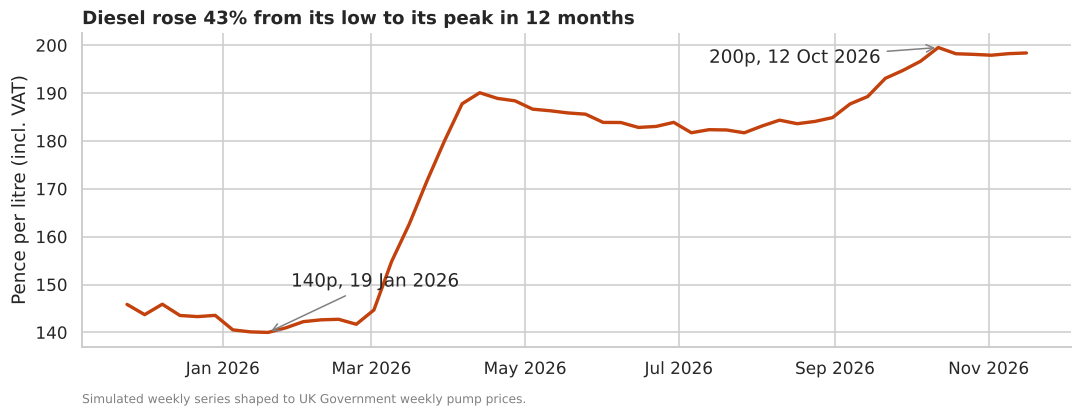

In [32]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prices["week_start"], prices["pump_ppl"], color="#C2410C", lw=2.2)

low_wk = prices.loc[prices["pump_ppl"].idxmin()]
peak_wk = prices.loc[prices["pump_ppl"].idxmax()]
for wk, offset in [(low_wk, (15, 30)), (peak_wk, (-150, -10))]:
    ax.annotate(f"{wk.pump_ppl:.0f}p, {wk.week_start:%d %b %Y}",
                xy=(wk.week_start, wk.pump_ppl), xytext=offset,
                textcoords="offset points", arrowprops=dict(arrowstyle="->", color="grey"))

rise = (peak_wk.pump_ppl / low_wk.pump_ppl - 1) * 100
ax.set_title(f"Diesel rose {rise:.0f}% from its low to its peak in 12 months", loc="left", fontweight="bold")
ax.set_ylabel("Pence per litre (incl. VAT)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.text(0, -0.18, "Simulated weekly series shaped to UK Government weekly pump prices.",
        transform=ax.transAxes, fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIG / "01_diesel_price.png", dpi=200, bbox_inches="tight")
plt.show()

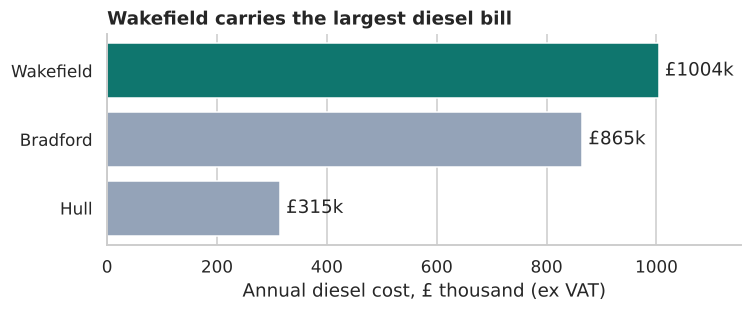

In [33]:
depot_cost = df.groupby("depot_name")["fuel_cost_gbp"].sum().sort_values() / 1000
colours = ["#94A3B8"] * (len(depot_cost) - 1) + ["#0F766E"]

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(depot_cost.index, depot_cost.values, color=colours)
ax.bar_label(bars, fmt="£%.0fk", padding=4)
ax.set_title(f"{depot_cost.idxmax()} carries the largest diesel bill", loc="left", fontweight="bold")
ax.set_xlabel("Annual diesel cost, £ thousand (ex VAT)")
ax.set_xlim(0, depot_cost.max() * 1.15)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "02_cost_by_depot.png", dpi=200, bbox_inches="tight")
plt.show()

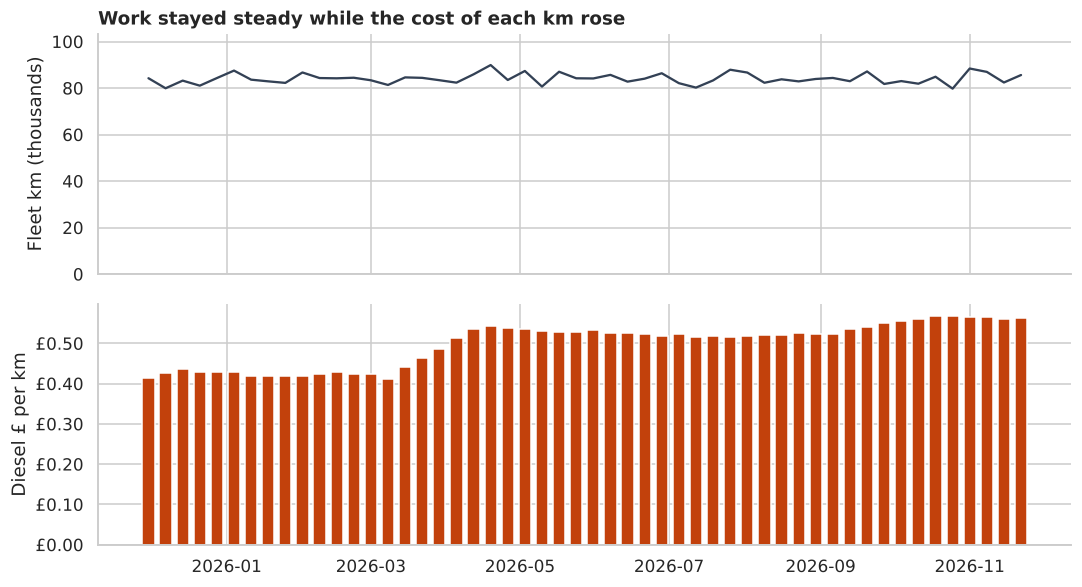

In [34]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)

ax1.plot(weekly.index, weekly["distance_km"] / 1000, color="#334155")
ax1.set_ylabel("Fleet km (thousands)")
ax1.set_ylim(0, weekly["distance_km"].max() / 1000 * 1.15)
ax1.set_title("Work stayed steady while the cost of each km rose", loc="left", fontweight="bold")

ax2.bar(weekly.index, weekly["cost_per_km"], width=5, color="#C2410C")
ax2.set_ylabel("Diesel £ per km")
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:.2f}"))

fig.tight_layout()
fig.savefig(FIG / "03_weekly_activity_cost.png", dpi=200, bbox_inches="tight")
plt.show()

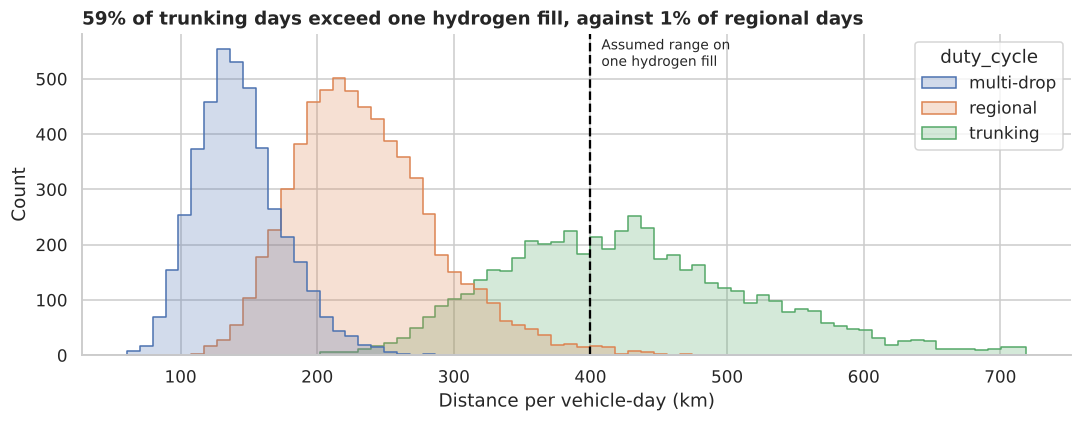

In [35]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=df, x="distance_km", hue="duty_cycle", bins=70, element="step",
             hue_order=["multi-drop", "regional", "trunking"], ax=ax)
ax.axvline(H2_RANGE_KM, ls="--", color="black")
ax.text(H2_RANGE_KM + 8, ax.get_ylim()[1] * 0.9, "Assumed range on\none hydrogen fill", fontsize=9)

over = df.groupby("duty_cycle")["within_h2_range"].mean().rsub(1).mul(100)
ax.set_title(f"{over['trunking']:.0f}% of trunking days exceed one hydrogen fill, "
             f"against {over['regional']:.0f}% of regional days", loc="left", fontweight="bold")
ax.set_xlabel("Distance per vehicle-day (km)")
fig.tight_layout()
fig.savefig(FIG / "04_daily_km_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

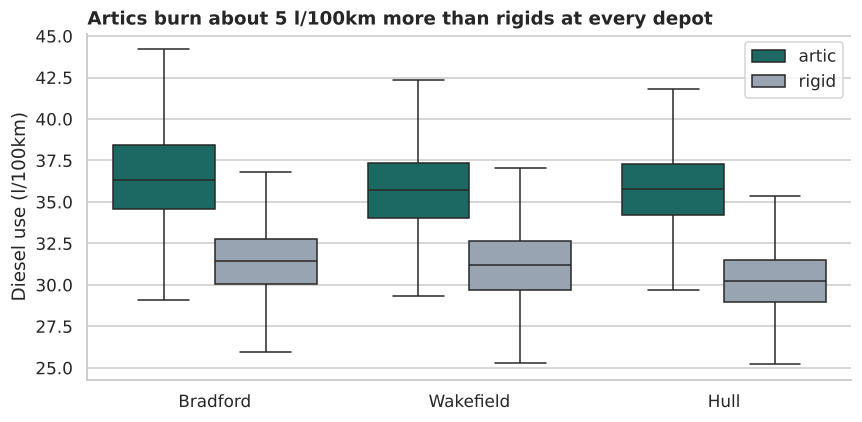

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="depot_name", y="l_per_100km", hue="vehicle_type",
            order=["Bradford", "Wakefield", "Hull"], hue_order=["artic", "rigid"],
            showfliers=False, palette=["#0F766E", "#94A3B8"], ax=ax)
ax.set_title("Artics burn about 5 l/100km more than rigids at every depot", loc="left", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Diesel use (l/100km)")
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIG / "05_fuel_use_by_depot.png", dpi=200, bbox_inches="tight")
plt.show()

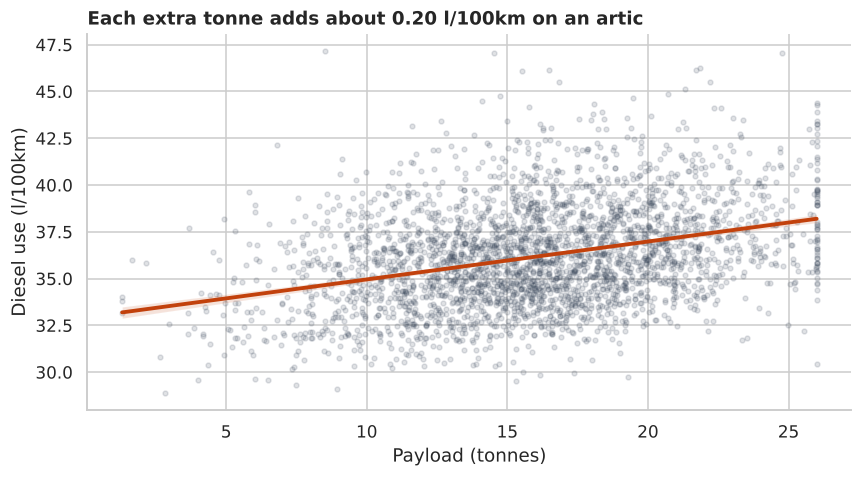

In [37]:
artics = df[df["vehicle_type"] == "artic"]
slope, intercept = np.polyfit(artics["payload_t"], artics["l_per_100km"], deg=1)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=artics.sample(3000, random_state=1), x="payload_t", y="l_per_100km",
            scatter_kws=dict(alpha=0.15, s=10, color="#334155"),
            line_kws=dict(color="#C2410C", lw=2.5), ax=ax)
ax.set_title(f"Each extra tonne adds about {slope:.2f} l/100km on an artic", loc="left", fontweight="bold")
ax.set_xlabel("Payload (tonnes)")
ax.set_ylabel("Diesel use (l/100km)")
fig.tight_layout()
fig.savefig(FIG / "06_payload_vs_fuel.png", dpi=200, bbox_inches="tight")
plt.show()

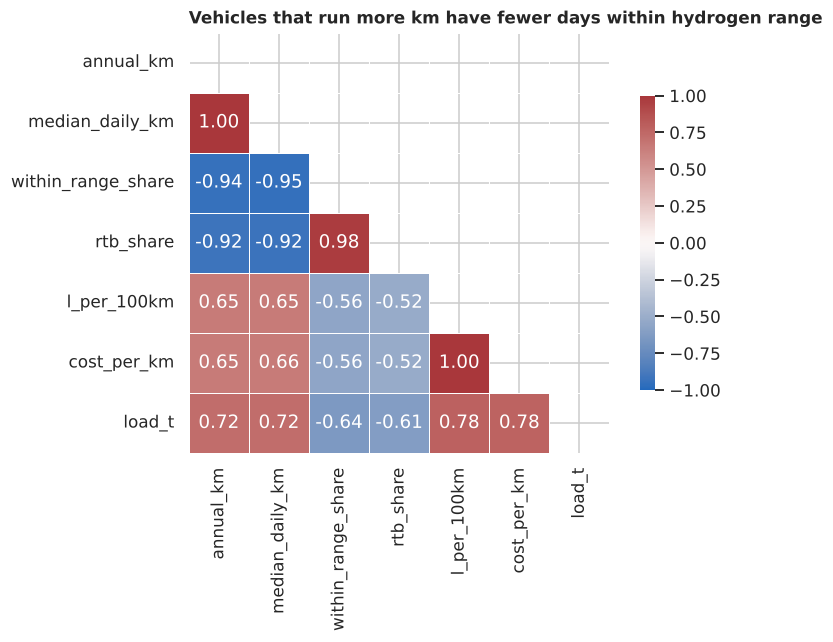

In [38]:
cols = ["annual_km", "median_daily_km", "within_range_share", "rtb_share",
        "l_per_100km", "cost_per_km", "load_t"]
corr = profile[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws=dict(shrink=0.7), ax=ax)
ax.set_title("Vehicles that run more km have fewer days within hydrogen range",
             loc="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "07_vehicle_kpi_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

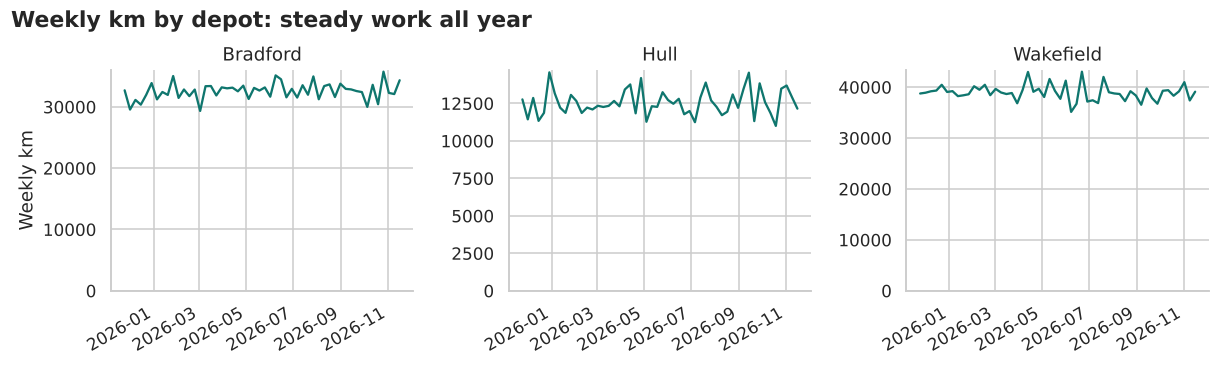

In [39]:
weekly_depot = df.groupby(["week_start", "depot_name"], as_index=False)["distance_km"].sum()

g = sns.relplot(data=weekly_depot, x="week_start", y="distance_km", col="depot_name",
                kind="line", height=3, aspect=1.25, color="#0F766E",
                facet_kws=dict(sharey=False))
g.set_titles("{col_name}")
g.set_axis_labels("", "Weekly km")
for ax in g.axes.flat:
    ax.set_ylim(0)
g.figure.autofmt_xdate()
g.figure.suptitle("Weekly km by depot: steady work all year", x=0.01, ha="left", y=1.05, fontweight="bold")
g.savefig(FIG / "08_weekly_km_by_depot.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Decision model

The model compares fuel cost only. It excludes vehicle price premiums, grants, maintenance and residual value.

### 7.1 Assumptions

In [40]:
DIESEL_PPL_BASE = 196.8                    # pump price, p/litre incl. VAT
H2_PRICE_BASE = 10.0                       # £/kg
H2_KG_PER_100 = {"artic": 9.0, "rigid": 6.5}

assumptions = pd.DataFrame([
    ("Diesel pump price (base)", DIESEL_PPL_BASE, "p/litre incl. VAT", "UK Government weekly road fuel prices, week to 16 Nov 2026"),
    ("VAT on diesel", 20, "%", "Reclaimable by VAT-registered hauliers"),
    ("Hydrogen price (base)", H2_PRICE_BASE, "£/kg", "Modelled 2026 contracted depot price of £9.5 to £10.5/kg (Harper, 2026)"),
    ("Hydrogen use, artic", H2_KG_PER_100["artic"], "kg/100km", "Assumption: industry reports cite 30 to 50 kg for 300 to 500 km"),
    ("Hydrogen use, rigid", H2_KG_PER_100["rigid"], "kg/100km", "Assumption, scaled from artic"),
    ("Hydrogen range per fill", H2_RANGE_KM, "km", "Assumption"),
    ("Diesel CO2e", CO2E_PER_L, "kg/litre", "DESNZ GHG conversion factors, diesel (average biofuel blend)"),
], columns=["assumption", "value", "unit", "source"])
assumptions

,assumption,value,unit,source
0,Diesel pump price (base),196.80,p/litre incl. VAT,"UK Government weekly road fuel prices, week to..."
1,VAT on diesel,20.00,%,Reclaimable by VAT-registered hauliers
2,Hydrogen price (base),10.00,£/kg,Modelled 2026 contracted depot price of £9.5 t...
3,"Hydrogen use, artic",9.00,kg/100km,Assumption: industry reports cite 30 to 50 kg ...
4,"Hydrogen use, rigid",6.50,kg/100km,"Assumption, scaled from artic"
5,Hydrogen range per fill,400.00,km,Assumption
6,Diesel CO2e,2.55,kg/litre,"DESNZ GHG conversion factors, diesel (average ..."


### 7.2 Break-even hydrogen price per truck

In [41]:
diesel_base = DIESEL_PPL_BASE / 100 / VAT
profile["h2_kg_per_100"] = profile["vehicle_type"].map(H2_KG_PER_100)

profile["breakeven_h2"] = diesel_base * profile["l_per_100km"] / profile["h2_kg_per_100"]
profile["annual_gap_gbp"] = profile["annual_km"] / 100 * (
    H2_PRICE_BASE * profile["h2_kg_per_100"] - diesel_base * profile["l_per_100km"])

profile.groupby("vehicle_type")[["breakeven_h2", "annual_gap_gbp"]].describe().T.round(2)

vehicle_type             artic     rigid
breakeven_h2   count     32.00     28.00
               mean       6.59      7.83
               std        0.36      0.36
               min        6.08      6.95
               25%        6.29      7.56
               50%        6.56      7.93
               75%        6.75      8.12
               max        7.62      8.35
annual_gap_gbp count     32.00     28.00
               mean  28,927.65  6,766.97
               std    8,336.29  1,778.98
               min   16,737.64  4,476.81
               25%   20,333.74  5,190.75
               50%   31,340.31  6,524.62
               75%   36,665.41  7,863.57
               max   39,824.53 10,769.25

### 7.3 Fleet sensitivity grid (diesel price × hydrogen price)

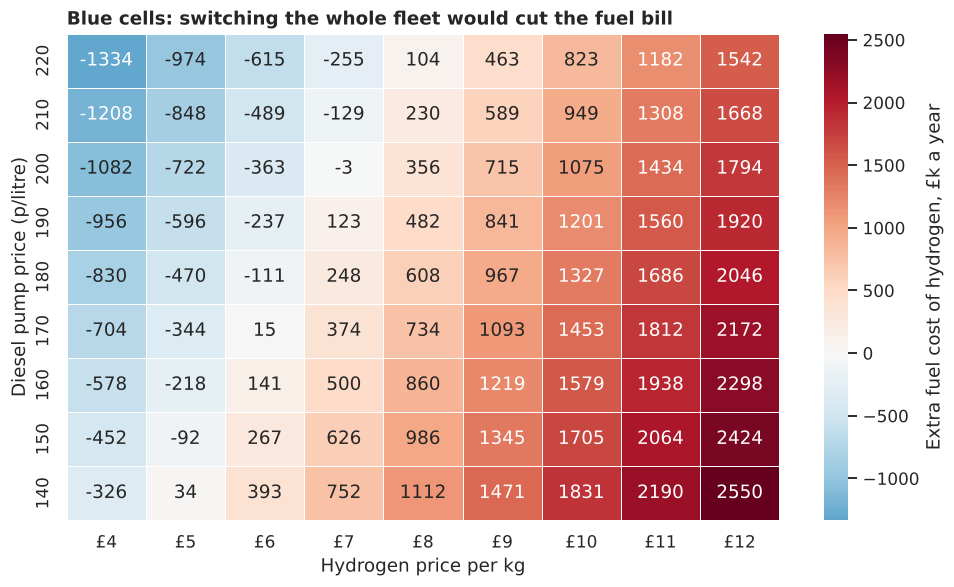

At 196.8p diesel, the fleet breaks even at £6.90/kg hydrogen.


In [42]:
fleet_diesel_l = profile["fuel_l"].sum()
fleet_h2_kg = (profile["annual_km"] / 100 * profile["h2_kg_per_100"]).sum()

diesel_grid = np.arange(140, 221, 10)        # pump p/litre
h2_grid = np.arange(4.0, 12.1, 1.0)          # £/kg

gap_grid = (h2_grid[None, :] * fleet_h2_kg
            - (diesel_grid[:, None] / 100 / VAT) * fleet_diesel_l) / 1000   # £k per year
gap_df = pd.DataFrame(gap_grid, index=diesel_grid, columns=[f"£{h:.0f}" for h in h2_grid])

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(gap_df, annot=True, fmt=".0f", cmap="RdBu_r", center=0, linewidths=0.4,
            cbar_kws=dict(label="Extra fuel cost of hydrogen, £k a year"), ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Hydrogen price per kg")
ax.set_ylabel("Diesel pump price (p/litre)")
ax.set_title("Blue cells: switching the whole fleet would cut the fuel bill", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "09_sensitivity_grid.png", dpi=200, bbox_inches="tight")
plt.show()

fleet_breakeven = diesel_base * fleet_diesel_l / fleet_h2_kg
print(f"At {DIESEL_PPL_BASE}p diesel, the fleet breaks even at £{fleet_breakeven:.2f}/kg hydrogen.")

### 7.4 Monte Carlo simulation (10,000 futures × 60 trucks)

In [43]:
N = 10_000
rng = np.random.default_rng(2026)

diesel_sim = rng.triangular(141, 185, 205, N) / 100 / VAT    # £/litre ex VAT, shape (N,)
h2_price_sim = rng.triangular(6.0, 10.0, 12.0, N)            # £/kg, shape (N,)
use_artic = rng.uniform(7.5, 10.5, N)
use_rigid = rng.uniform(5.5, 7.5, N)

is_artic = profile["vehicle_type"].eq("artic").to_numpy()   # shape (60,)
km = profile["annual_km"].to_numpy()
l100 = profile["l_per_100km"].to_numpy()

h2_use = np.where(is_artic[None, :], use_artic[:, None], use_rigid[:, None])   # (N, 60)
diesel_cost = diesel_sim[:, None] * l100[None, :] * km[None, :] / 100           # (N, 60)
h2_cost = h2_price_sim[:, None] * h2_use * km[None, :] / 100                    # (N, 60)
gap_sim = h2_cost - diesel_cost                                                 # (N, 60)

profile["p_h2_cheaper"] = (gap_sim < 0).mean(axis=0)     # per truck, across futures
fleet_gap = gap_sim.sum(axis=1) / 1000                    # per future, across trucks
p5, p50, p95 = np.percentile(fleet_gap, [5, 50, 95])
print(f"Shape of the simulation: {gap_sim.shape}")
print(f"Fleet extra cost of hydrogen: median £{p50:,.0f}k a year (90% range £{p5:,.0f}k to £{p95:,.0f}k)")
print(f"Chance the whole fleet saves money: {(fleet_gap < 0).mean():.1%}")

Shape of the simulation: (10000, 60)
Fleet extra cost of hydrogen: median £1,114k a year (90% range £210k to £1,990k)
Chance the whole fleet saves money: 1.7%


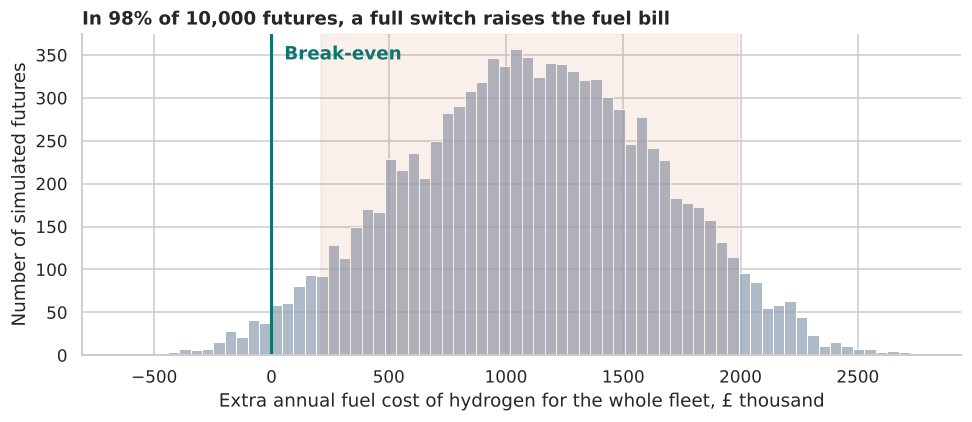

In [44]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(fleet_gap, bins=70, color="#94A3B8", ax=ax)
ax.axvline(0, color="#0F766E", lw=2)
ax.axvspan(p5, p95, color="#C2410C", alpha=0.08)
ax.text(0, ax.get_ylim()[1] * 0.92, "  Break-even", color="#0F766E", fontweight="bold")
ax.set_title(f"In {(fleet_gap >= 0).mean():.0%} of 10,000 futures, a full switch raises the fuel bill",
             loc="left", fontweight="bold")
ax.set_xlabel("Extra annual fuel cost of hydrogen for the whole fleet, £ thousand")
ax.set_ylabel("Number of simulated futures")
fig.tight_layout()
fig.savefig(FIG / "10_monte_carlo.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.5 Readiness ranking

Weighted score from range fit (0.30), back-to-base share (0.20), station access (0.20), Monte Carlo economics (0.20) and annual km (0.10), each min-max scaled. The top eight are unchanged when economics is weighted at 0.40 and range fit at 0.10.

In [45]:
def minmax(s: pd.Series) -> pd.Series:
    return (s - s.min()) / (s.max() - s.min())

WEIGHTS = {"range_fit": 0.30, "back_to_base": 0.20, "station_access": 0.20,
           "economics": 0.20, "scale": 0.10}

def readiness(p: pd.DataFrame, weights: dict) -> pd.Series:
    factors = pd.DataFrame({
        "range_fit": p["within_range_share"],
        "back_to_base": p["rtb_share"],
        "station_access": 1 - minmax(p["km_to_hrs"]),
        "economics": minmax(p["p_h2_cheaper"]),
        "scale": minmax(p["annual_km"]),
    })
    return sum(factors[name] * w for name, w in weights.items())

profile["readiness"] = readiness(profile, WEIGHTS)
profile["rank"] = profile["readiness"].rank(ascending=False).astype(int)

shortlist = profile.nsmallest(8, "rank")
shortlist[["rank", "vehicle_id", "depot_name", "vehicle_type", "duty_cycle", "annual_km",
           "within_range_share", "breakeven_h2", "p_h2_cheaper", "co2e_t", "readiness"]]

,rank,vehicle_id,depot_name,vehicle_type,duty_cycle,annual_km,within_range_share,breakeven_h2,p_h2_cheaper,co2e_t,readiness
13,1,V014,Bradford,rigid,regional,"60,757.90",1.00,8.32,0.13,51.10,0.91
22,2,V023,Bradford,rigid,regional,"63,375.60",0.99,8.21,0.12,52.57,0.89
29,3,V030,Bradford,rigid,regional,"65,784.50",0.99,8.15,0.11,54.21,0.89
30,4,V031,Wakefield,rigid,regional,"60,438.10",0.99,8.35,0.14,51.01,0.86
31,5,V032,Bradford,rigid,regional,"64,212.30",0.99,7.96,0.09,51.65,0.85
12,6,V013,Bradford,rigid,multi-drop,"39,870.30",1.00,8.05,0.10,32.45,0.84
2,7,V003,Wakefield,rigid,regional,"64,533.00",0.99,8.13,0.11,53.01,0.82
44,8,V045,Wakefield,rigid,multi-drop,"38,542.60",1.00,8.21,0.12,31.97,0.81


In [46]:
print("Shortlist by depot:      ", shortlist["depot_name"].value_counts().to_dict())
print("Shortlist by duty cycle: ", shortlist["duty_cycle"].value_counts().to_dict())
print(f"Tailpipe CO2e these 8 trucks emit a year: {shortlist['co2e_t'].sum():,.0f} t "
      f"({shortlist['co2e_t'].sum() / profile['co2e_t'].sum():.0%} of the fleet)")
print(f"Extra fuel cost at base prices: £{shortlist['annual_gap_gbp'].sum():,.0f} a year")

Shortlist by depot:       {'Bradford': 5, 'Wakefield': 3}
Shortlist by duty cycle:  {'regional': 6, 'multi-drop': 2}
Tailpipe CO2e these 8 trucks emit a year: 378 t (10% of the fleet)
Extra fuel cost at base prices: £54,299 a year


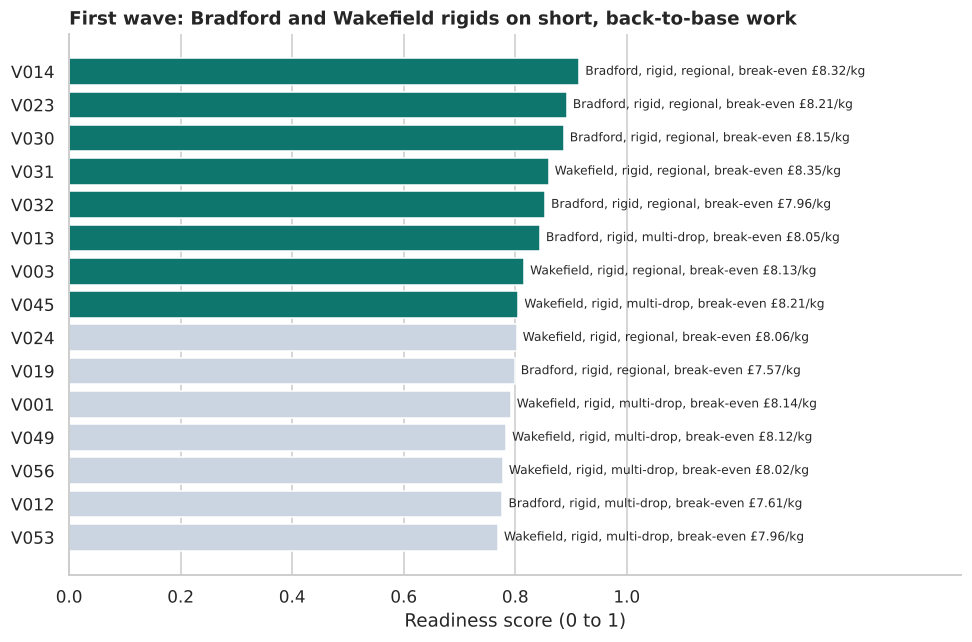

In [47]:
top15 = profile.nsmallest(15, "rank").sort_values("readiness")
colours = np.where(top15["rank"] <= 8, "#0F766E", "#CBD5E1")

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top15["vehicle_id"], top15["readiness"], color=colours)
labels = [f"{r.depot_name}, {r.vehicle_type}, {r.duty_cycle}, break-even £{r.breakeven_h2:.2f}/kg"
          for r in top15.itertuples()]
ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.set_xlim(0, 1.6)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel("Readiness score (0 to 1)")
ax.grid(axis="y", visible=False)
ax.set_title(f"First wave: {shortlist['depot_name'].mode()[0]} and "
             f"{shortlist['depot_name'].value_counts().index[-1]} {shortlist['vehicle_type'].mode()[0]}s "
             f"on short, back-to-base work", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "11_readiness_ranking.png", dpi=200, bbox_inches="tight")
plt.show()

profile.to_csv(CLEAN / "vehicle_profile.csv", index=False)

## 8. Findings

In [48]:
print(f"""1. Not yet for the whole fleet. At {DIESEL_PPL_BASE:.0f}p diesel and £{H2_PRICE_BASE:.0f}/kg hydrogen,
   a full switch adds about £{profile['annual_gap_gbp'].sum() / 1000:,.0f}k a year in fuel.
   It pays only if hydrogen falls to about £{fleet_breakeven:.2f}/kg.

2. Hydrogen rarely wins on fuel cost today. In only {(fleet_gap < 0).mean():.0%} of 10,000 simulated
   futures is it cheaper for the whole fleet.

3. Start small and in the right place. The top 8 trucks are mostly {shortlist['depot_name'].mode()[0]}
   {shortlist['vehicle_type'].mode()[0]}s on {shortlist['duty_cycle'].mode()[0]} work: short days, back at base, near a station.
   They emit {shortlist['co2e_t'].sum():,.0f} t CO2e a year. A pilot would cost about
   £{shortlist['annual_gap_gbp'].sum() / 1000:,.0f}k a year extra in fuel at base prices.

4. Trunking trucks burn the most diesel but are the worst fit today:
   {over['trunking']:.0f}% of their days exceed one fill. Revisit them as the station network grows.""")

1. Not yet for the whole fleet. At 197p diesel and £10/kg hydrogen,
   a full switch adds about £1,115k a year in fuel.
   It pays only if hydrogen falls to about £6.90/kg.

2. Hydrogen rarely wins on fuel cost today. In only 2% of 10,000 simulated
   futures is it cheaper for the whole fleet.

3. Start small and in the right place. The top 8 trucks are mostly Bradford
   rigids on regional work: short days, back at base, near a station.
   They emit 378 t CO2e a year. A pilot would cost about
   £54k a year extra in fuel at base prices.

4. Trunking trucks burn the most diesel but are the worst fit today:
   59% of their days exceed one fill. Revisit them as the station network grows.


### Limitations

* Simulated data: realistic patterns, invented company.
* Fuel cost only: no vehicle premium, grants, maintenance or residual value.
* Tailpipe CO2e only: hydrogen's footprint depends on how it is produced.
* Fixed 400 km range per fill; real range varies with load, weather and terrain.
* Readiness weights are a reasoned judgement, tested with an alternative set.

In [49]:
con.close()
print("Figures saved:", sorted(p.name for p in FIG.glob("*.png")))

Figures saved: ['01_diesel_price.png', '02_cost_by_depot.png', '03_weekly_activity_cost.png', '04_daily_km_distribution.png', '05_fuel_use_by_depot.png', '06_payload_vs_fuel.png', '07_vehicle_kpi_correlation.png', '08_weekly_km_by_depot.png', '09_sensitivity_grid.png', '10_monte_carlo.png', '11_readiness_ranking.png']
